In [5]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

## Consider high-level electric consumption anomaly

In [1]:
df = pd.read_pickle('../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 4]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df['blockgroupID'] = df['blockID'].str[:5]
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

NameError: name 'pd' is not defined

In [7]:
boundary_block = pd.read_csv('../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [8]:
boundary_block_group = boundary_block.copy()
boundary_block_group["blockgroupID"] = boundary_block_group["blockID"].astype(str).str[:5]
boundary_block_group = boundary_block_group[['tractID','blockID','blockgroupID','geoID','geometry','centroid']]

In [10]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID",'blockgroupID']

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [11]:
df1.head(2)

,badge,date,address,district,tractID,blockID,blockgroupID,INT_4h_1,INT_4h_2,INT_4h_3,INT_4h_4,INT_4h_5,INT_4h_6
0,E162956,2018-04-01,46.0,POINT (-84.30334 30.388433),1801,18011011,18011,9.78,7.94,8.06,1.59,1.62,1.56
1,E162956,2018-04-02,46.0,POINT (-84.30334 30.388433),1801,18011011,18011,1.28,1.78,6.11,10.91,2.81,3.91


In [12]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID",'blockgroupID']

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# TODO: 用你的 30 天替换这里（要包含你希望对齐的那 30 个 calendar day）
day_range = pd.date_range("2018-04-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [13]:
df2.head(2)

,badge,address,district,tractID,blockID,blockgroupID,t000,t001,t002,t003,t004,t005,t006,t007,t008,t009,t010,t011,t012,t013,t014,t015,t016,t017,t018,t019,t020,t021,t022,t023,t024,t025,t026,t027,t028,t029,t030,t031,t032,t033,t034,t035,t036,t037,t038,t039,t040,t041,t042,t043,t044,t045,t046,t047,t048,t049,t050,t051,t052,t053,t054,t055,t056,t057,t058,t059,t060,t061,t062,t063,t064,t065,t066,t067,t068,t069,t070,t071,t072,t073,t074,t075,t076,t077,t078,t079,t080,t081,t082,t083,t084,t085,t086,t087,t088,t089,t090,t091,t092,t093,t094,t095,t096,t097,t098,t099,t100,t101,t102,t103,t104,t105,t106,t107,t108,t109,t110,t111,t112,t113,t114,t115,t116,t117,t118,t119,t120,t121,t122,t123,t124,t125,t126,t127,t128,t129,t130,t131,t132,t133,t134,t135,t136,t137,t138,t139,t140,t141,t142,t143,t144,t145,t146,t147,t148,t149,t150,t151,t152,t153,t154,t155,t156,t157,t158,t159,t160,t161,t162,t163,t164,t165,t166,t167,t168,t169,t170,t171,t172,t173,t174,t175,t176,t177,t178,t179
0,E162956,46.0,POINT (-84.30334 30.388433),1801,18011011,18011,9.78,7.94,8.06,1.59,1.62,1.56,1.28,1.78,6.11,10.91,2.81,3.91,1.96,4.22,1.05,1.51,1.63,1.59,1.16,2.58,1.26,1.04,2.86,7.67,6.41,4.57,0.91,1.15,1.18,4.98,1.19,4.23,1.93,1.74,2.02,1.21,1.1,2.37,2.68,3.30,8.56,3.61,1.60,1.26,4.21,6.80,5.70,3.20,1.31,3.92,1.14,1.02,2.55,9.35,1.15,5.06,1.15,0.91,3.95,6.77,6.25,5.05,0.96,1.04,2.48,2.4,1.14,2.80,1.05,0.93,3.17,2.45,1.18,2.76,1.10,4.89,1.58,1.75,1.38,2.25,3.10,2.36,1.59,2.17,1.37,1.12,0.00,4.26,1.76,6.66,6.78,6.42,3.25,1.26,6.15,3.39,1.18,3.64,0.93,0.96,4.56,6.69,6.46,3.88,1.11,1.05,1.20,1.98,1.42,3.35,0.99,1.15,1.21,1.72,1.52,3.27,2.31,3.92,2.18,1.38,1.32,1.26,4.13,3.48,2.08,2.65,1.30,5.33,2.43,1.34,1.46,1.58,1.45,2.33,1.35,1.17,4.57,1.84,1.37,2.72,1.03,1.05,2.12,1.71,2.40,1.68,6.29,5.85,3.06,1.74,1.42,2.59,0.94,1.09,2.35,1.78,1.22,2.90,1.28,3.19,4.04,5.91,1.26,3.10,4.09,4.24,2.39,1.64,1.44,3.57,7.00,3.50,2.77,3.25,1.84,3.09,1.60,3.02,4.02,3.37
1,E162959,36.0,POINT (-84.2839 30.493797),1602,16022007,16022,4.90,5.98,8.11,8.72,13.98,6.91,2.26,9.44,2.91,3.40,12.16,12.24,1.87,9.42,2.98,9.00,8.51,12.48,2.51,8.26,5.55,5.29,14.53,3.80,2.25,10.58,7.19,2.91,10.57,5.64,2.21,11.96,4.57,5.43,3.31,3.40,3.4,3.19,2.12,2.73,2.81,4.02,3.98,3.69,3.29,1.99,7.18,10.22,2.02,9.97,2.60,3.49,14.57,7.99,2.01,7.83,3.14,2.74,3.29,7.33,5.48,12.00,2.90,5.98,9.41,5.3,4.84,8.98,5.38,3.40,11.27,8.16,1.86,6.13,3.02,4.93,9.57,5.40,2.12,3.88,4.44,9.51,21.20,19.58,3.14,2.94,18.22,8.57,8.51,8.84,7.56,8.83,7.40,2.69,8.57,7.11,7.33,15.20,6.83,2.37,7.55,5.74,3.03,7.75,3.83,3.00,22.17,9.22,1.90,7.51,2.34,7.33,6.71,4.05,3.14,3.22,2.44,2.21,2.41,2.47,2.50,2.16,2.34,1.99,2.31,2.69,2.71,2.30,2.97,10.60,16.61,12.42,3.08,12.63,7.11,7.98,12.58,10.95,1.72,8.22,3.26,2.71,4.64,6.90,2.04,4.81,4.09,2.87,12.98,8.62,2.09,7.91,3.50,3.01,14.98,3.78,2.42,3.39,4.49,5.30,12.82,4.96,3.35,3.31,4.19,7.71,24.75,11.19,2.55,1.95,4.19,12.97,23.02,13.75,2.32,8.19,4.14,6.97,12.82,8.22


In [14]:
import re
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols)  # t000,t001,...,t179
X = df2[feat_cols].to_numpy(dtype=np.float64)  # 形状 (N, 180)
assert X.shape[1] == 180
assert X.shape[0] == len(df2)

In [15]:
z = np.asarray(X, dtype=float).ravel()
z = z[np.isfinite(z)]
thresh_high = np.quantile(z, 0.90)    
print(f"90% 阈值: {thresh_high:.2f}")

90% 阈值: 9.98


In [16]:
thresh_low = np.quantile(z, 0.05)    
print(f"5% 阈值: {thresh_low:.2f}")    

5% 阈值: 0.12


In [17]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [18]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X <= thresh_low, axis=1)
df2["prop_low"] = prop

In [19]:
df2 = df2[df2['prop_low'] <= 0.7]
df3 = df2[['badge','blockID','prop_high','prop_low']]
df3 = (
    df3.groupby("blockID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)

In [20]:
geo = geopd.GeoDataFrame(boundary_block).copy()
df3['blockID'] = df3['blockID'].astype(int)
df3['blockID'] = df3['blockID'].astype(str)
geo['blockID'] = geo['blockID'].astype(str)
geo_data = geo.merge(
    df3[["blockID","prop_high","prop_low"]],
    left_on="blockID",
    right_on="blockID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["blockID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(2548, 7)


,tractID,blockID,geoID,geometry,centroid,prop_high,prop_low
0,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.116823,0.021362
1,1901,19011015,120730019011015,"POLYGON ((-84.32835 30.41138, -84.32818 30.411...",POINT (-84.31403 30.41059),0.110225,0.009662


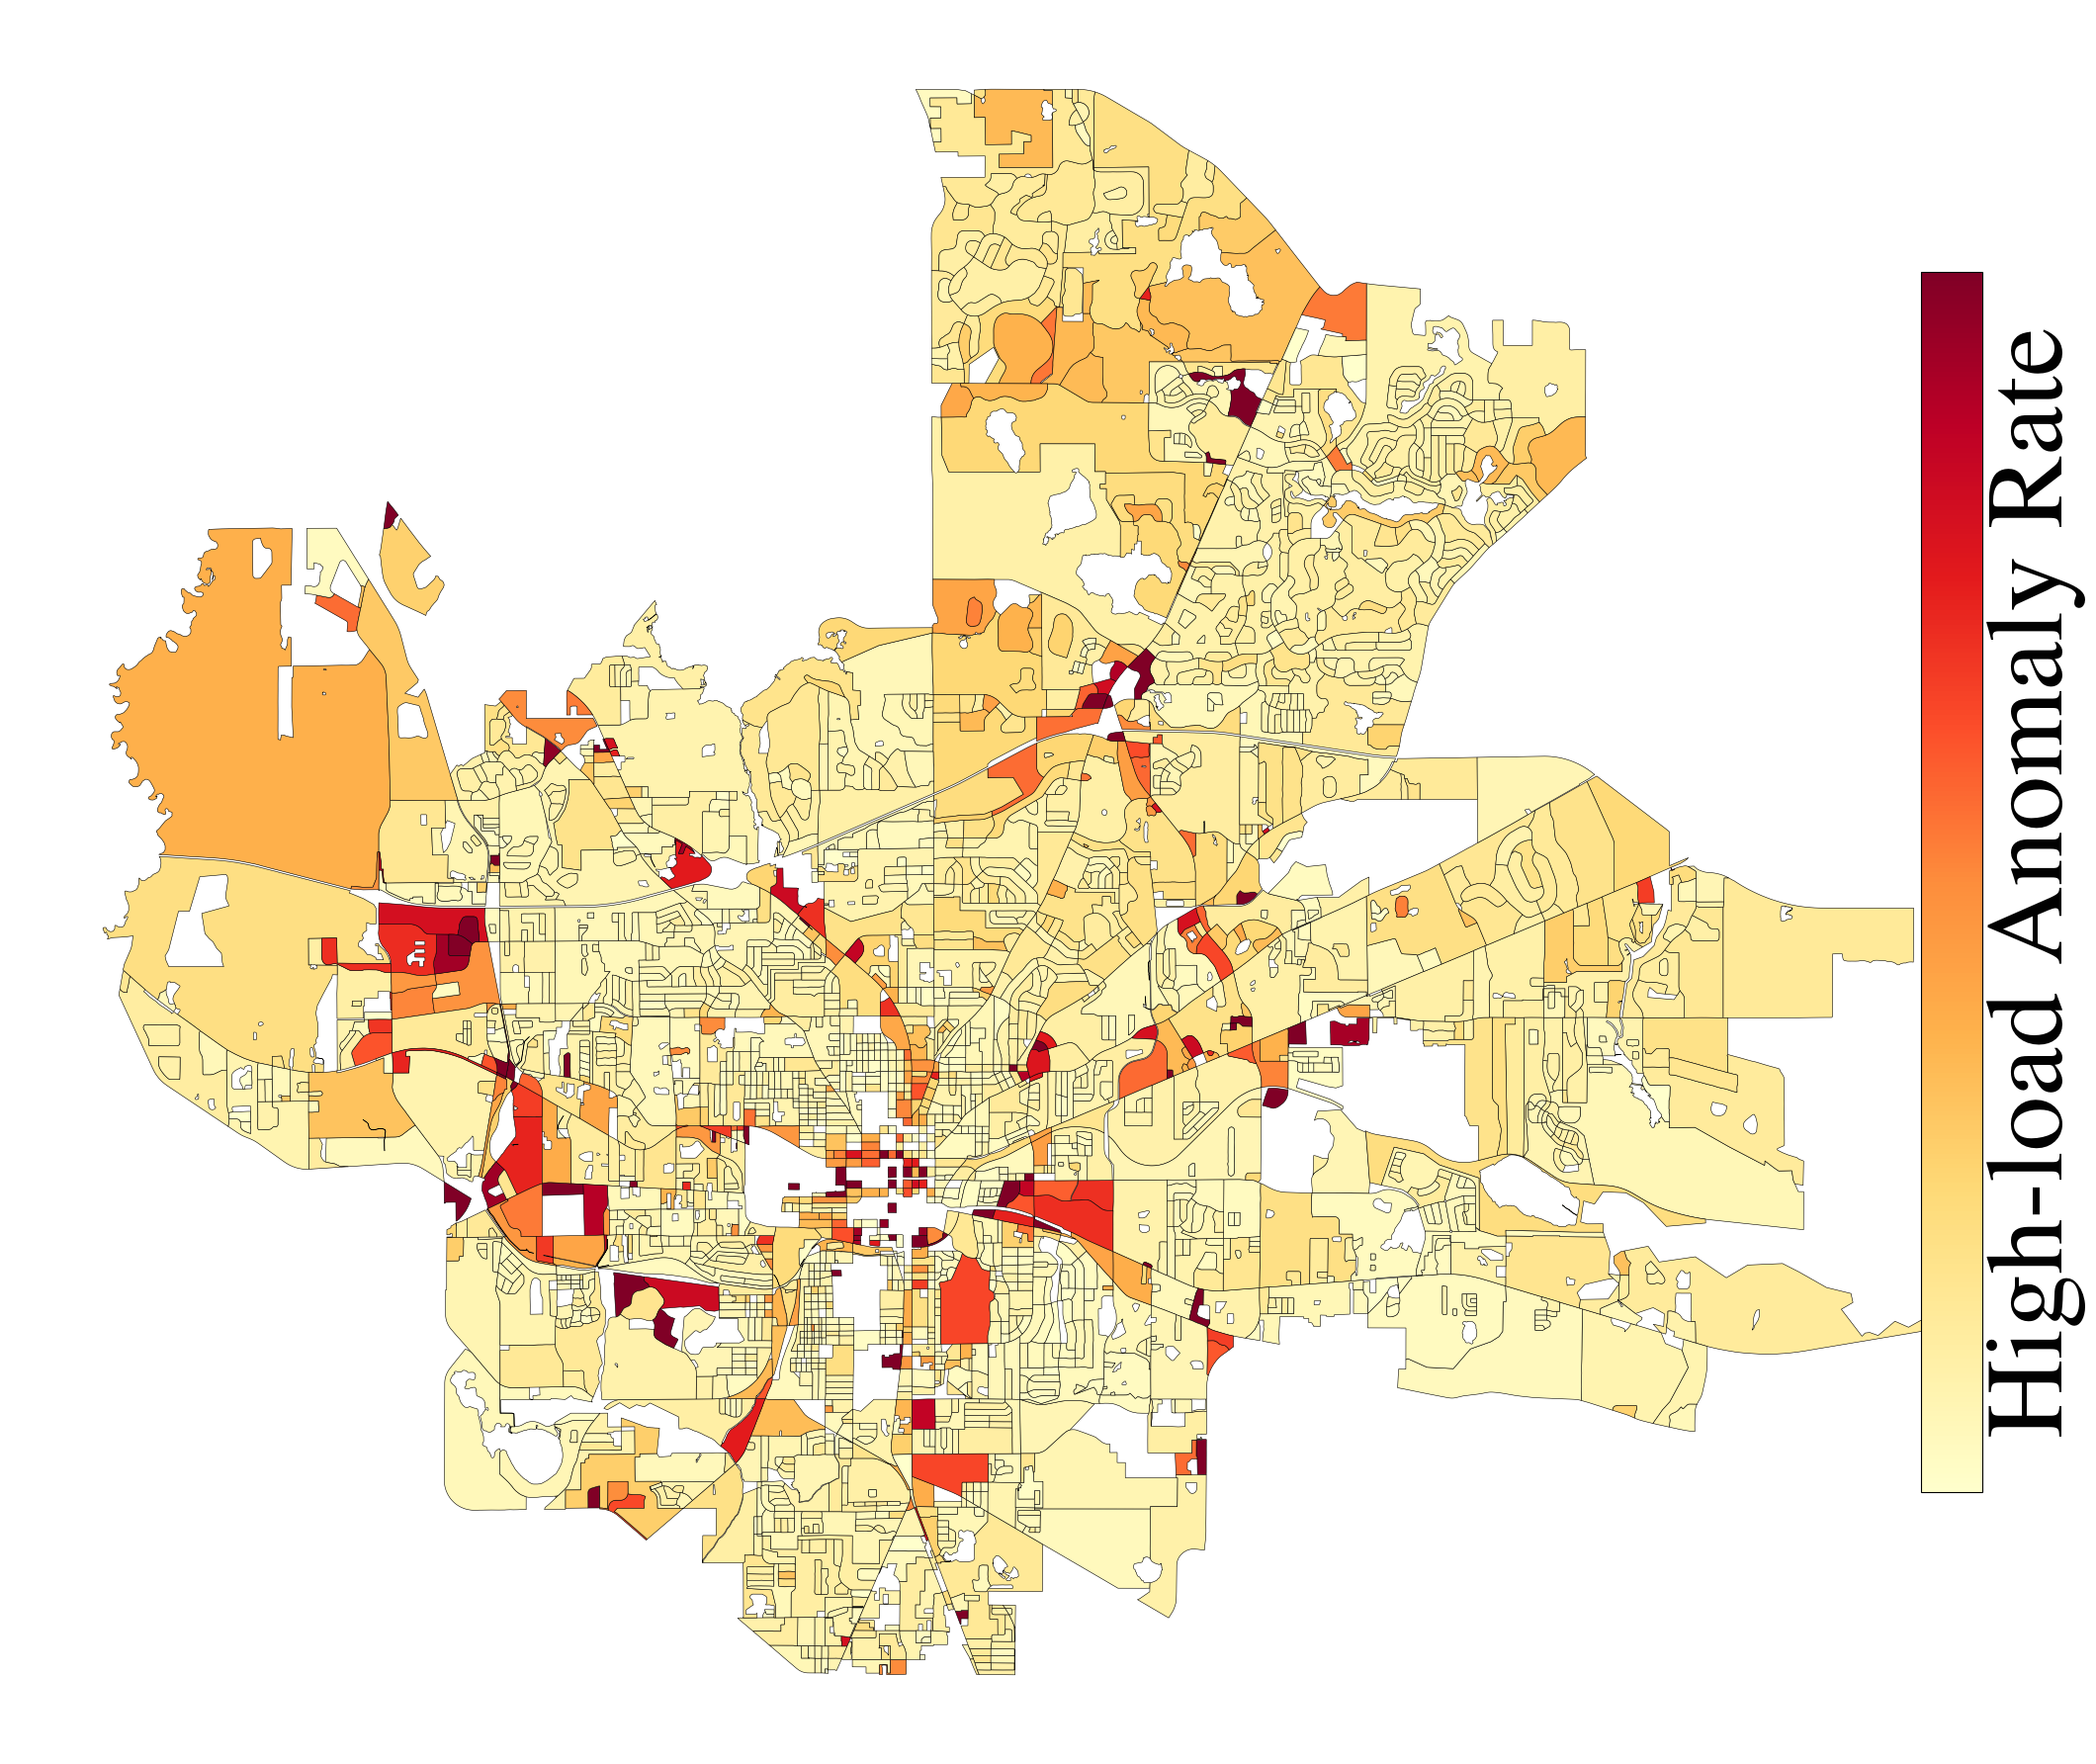

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))

color_col = "prop_high"

geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={
        "label": "High-load Anomalies Rate",
        "orientation": "vertical",
        "shrink": 0.7,
        "pad": -0.05,   # legend 和地图之间的距离
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)

# 获取 colorbar axis
cax = fig.axes[-1]

# 调整 colorbar 刻度字体大小
#cax.tick_params(labelsize=40)
cax.set_yticks([])
cax.set_yticklabels([])

# 调整 colorbar label 字体大小
cax.set_ylabel("High-load Anomaly Rate", fontsize=80)

# 关闭坐标轴
ax.set_axis_off()

# 手动缩小 figure 内部空白
plt.subplots_adjust(
    left=0.01,
    right=0.93,
    top=0.99,
    bottom=0.01,
)

# 保存论文图，自动裁剪外部空白
fig.savefig(
    "../Analysis/Plot/high_load_anomaly_map.png",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

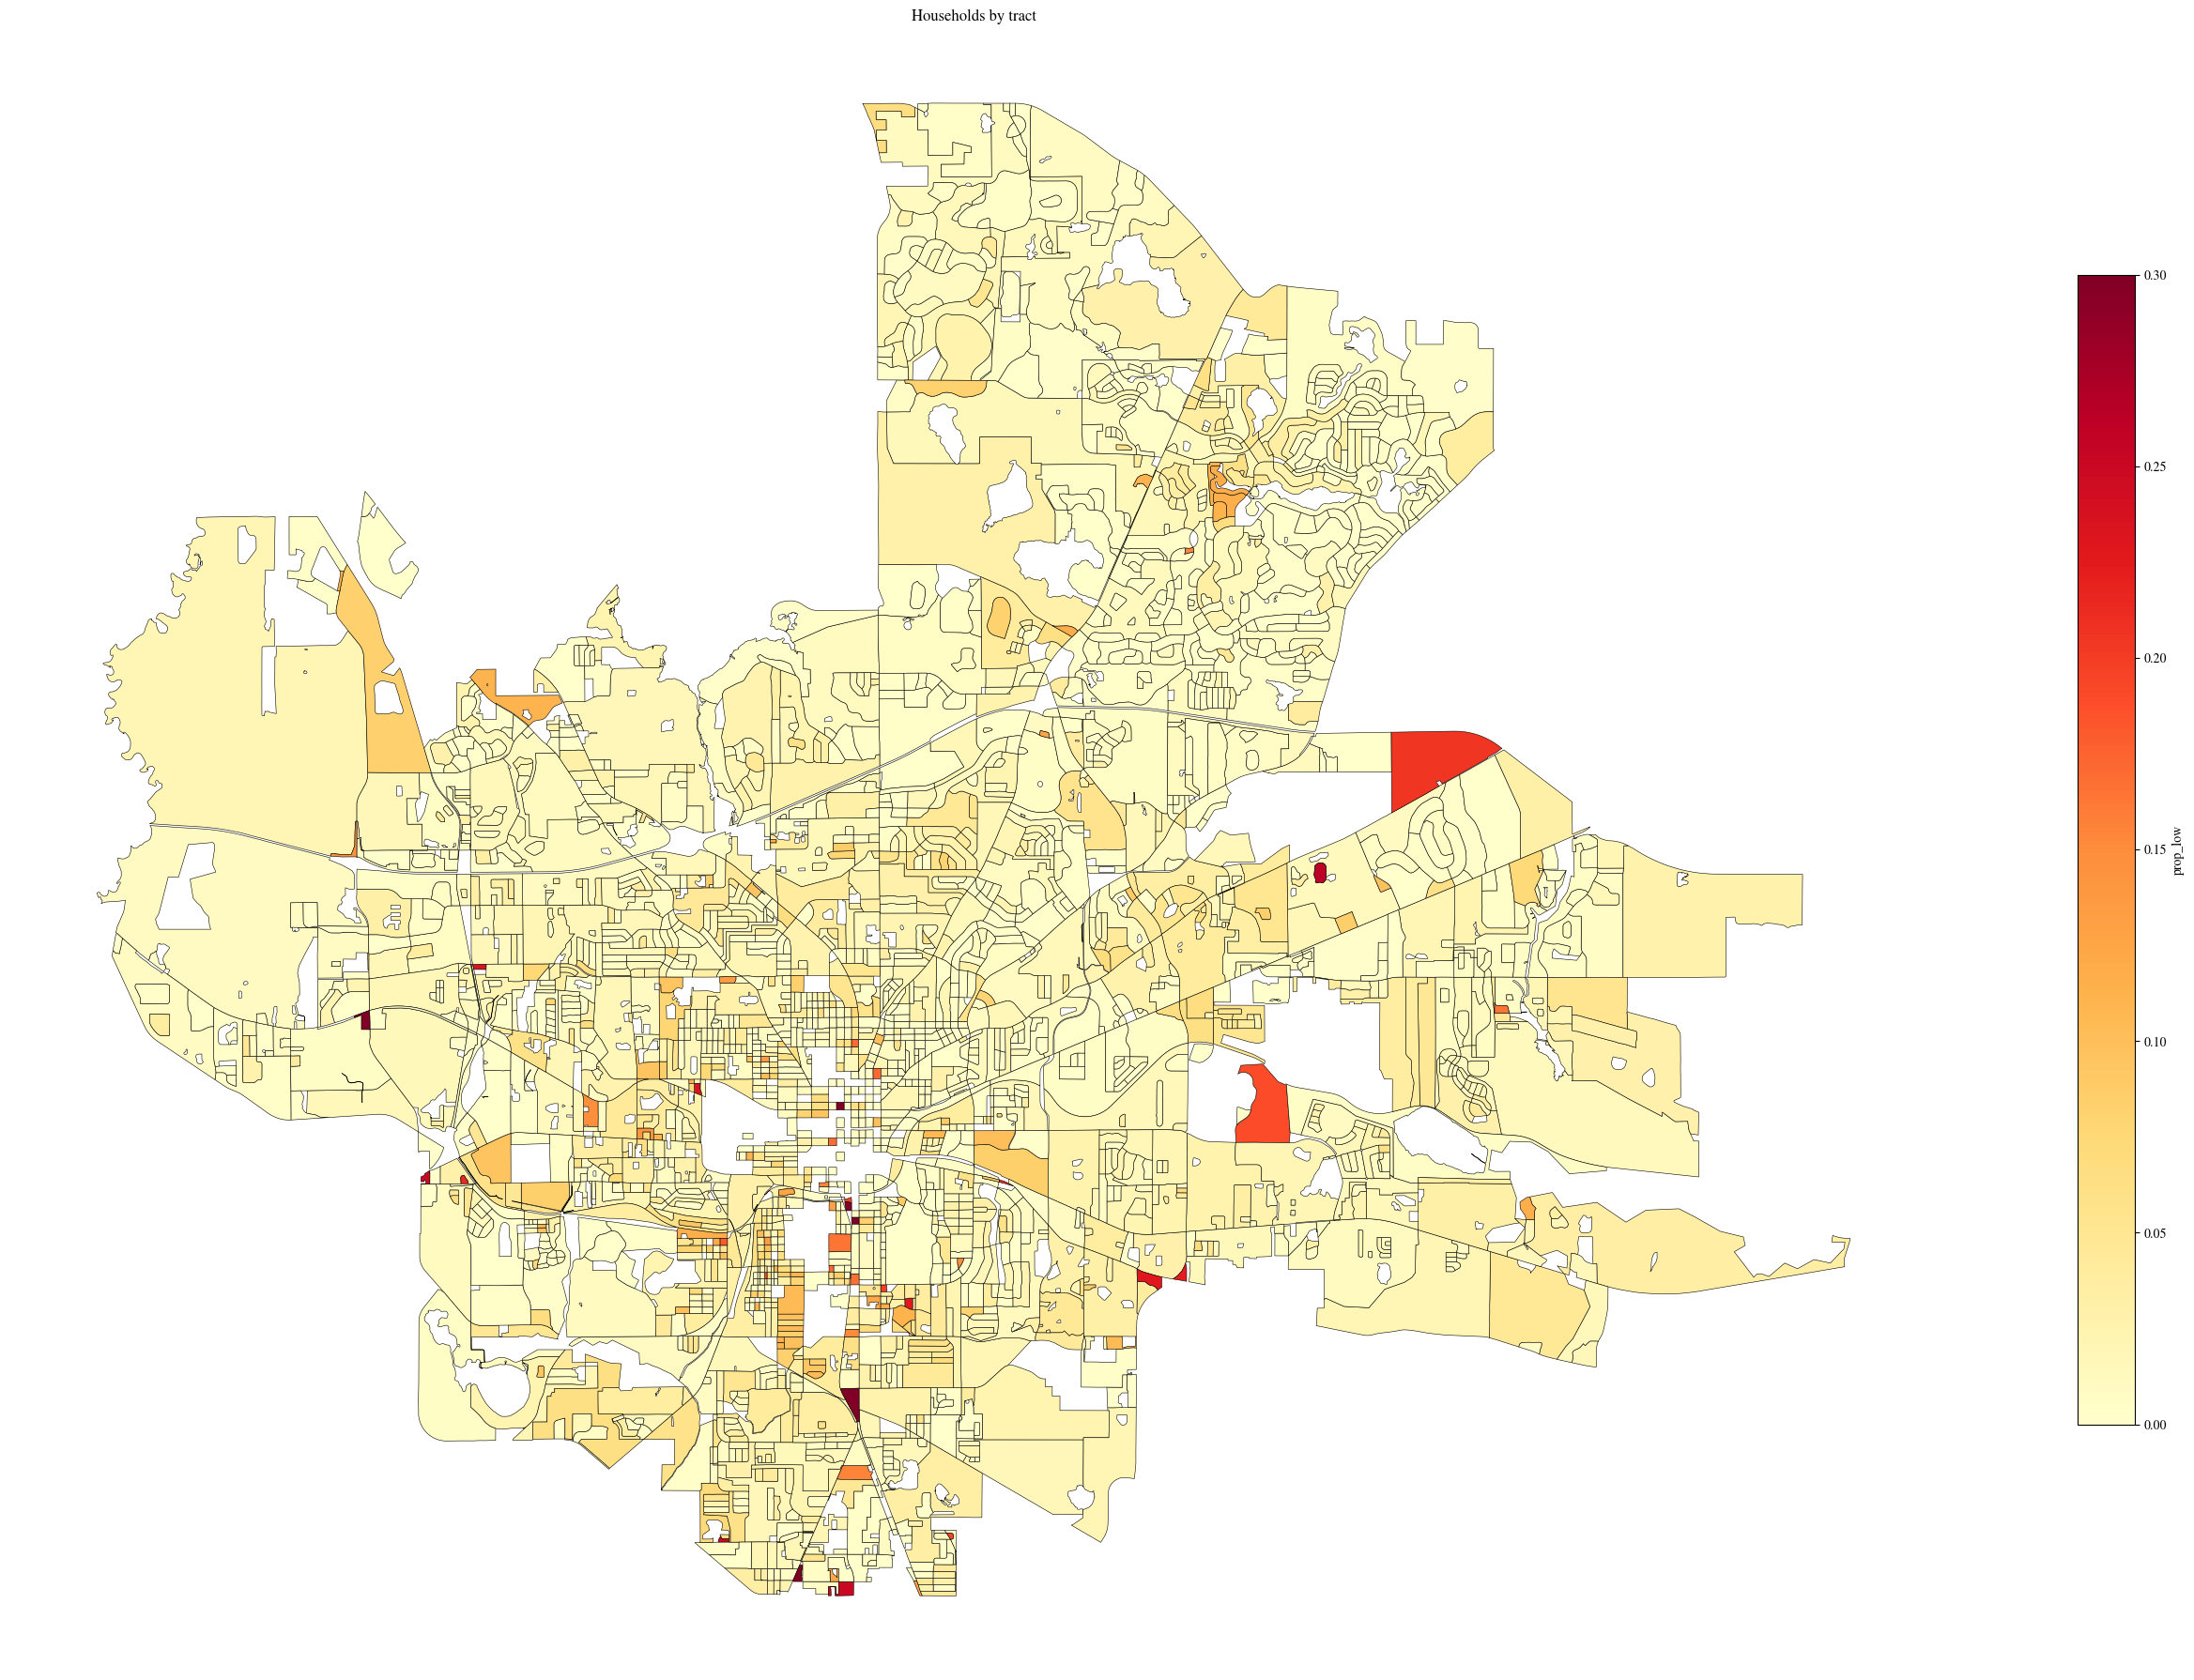

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
# 制图字段（有人口列时可改为 "households"）
color_col = "prop_low"
geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    # vmin=10,
    vmax=0.3,
    legend_kwds={
        "label": "prop_low",
        "orientation": "vertical",
        "shrink": 0.7,
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
ax.set_title("Households by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [23]:
df4 = df2[['badge','blockgroupID','prop_high','prop_low']]
df4 = (
    df4.groupby("blockgroupID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)

In [24]:
geo = geopd.GeoDataFrame(boundary_block_group).copy()
df4['blockgroupID'] = df4['blockgroupID'].astype(int)
df4['blockgroupID'] = df4['blockgroupID'].astype(str)
geo['blockgroupID'] = geo['blockgroupID'].astype(str)
geo_data = geo.merge(
    df4[["blockgroupID","prop_high","prop_low"]],
    left_on="blockgroupID",
    right_on="blockgroupID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["blockgroupID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(145, 8)


,tractID,blockID,blockgroupID,geoID,geometry,centroid,prop_high,prop_low
0,2505,25054048,25054,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322),0.088129,0.027609
1,1801,18012017,18012,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.090240,0.017660


In [25]:
import numpy as np
import geopandas as geopd
from sklearn.neighbors import kneighbors_graph

# 1. 每个 block 只保留一行，保证 W 和 geo_data 一一对应
geo_data = geo_data.drop_duplicates("geoID").copy()
geo_data = geo_data.reset_index(drop=True)

# 2. 确保 centroid 是 GeoSeries
# 如果 centroid 已经是 shapely Point，这一步可以保留，不影响
geo_data["centroid"] = geopd.GeoSeries(geo_data["centroid"], crs="EPSG:4326")

# 3. 用 centroid 构造 GeoDataFrame
centroid_gdf = geopd.GeoDataFrame(
    geo_data[["blockgroupID", "geoID", "prop_high", "prop_low", "centroid"]].copy(),
    geometry="centroid",
    crs="EPSG:4326"
)

# 4. 投影到米制坐标系
centroid_gdf = centroid_gdf.to_crs(epsg=3857)

# 5. 提取 centroid 坐标
coords = np.column_stack([
    centroid_gdf.geometry.x.values,
    centroid_gdf.geometry.y.values
])

# 6. 找最近的 5 个 block，构造 KNN 邻接矩阵
W = kneighbors_graph(
    coords,
    n_neighbors=1,
    mode="connectivity",
    include_self=False
)

# 7. row-normalization
row_sum = np.asarray(W.sum(axis=1)).ravel()
row_sum[row_sum == 0] = 1
W_norm = W.multiply(1 / row_sum[:, None])

In [26]:
def add_z_and_lag(df, col, W_norm, name):
    A = df[col].values.astype(float)

    z = (A - A.mean()) / A.std()
    lag = W_norm @ z

    df[f"z_{name}"] = z
    df[f"lag_{name}"] = lag

    return df

geo_data = add_z_and_lag(geo_data, "prop_high", W_norm, "high")
geo_data = add_z_and_lag(geo_data, "prop_low", W_norm, "low")

In [27]:
geo_data.head(2)

,tractID,blockID,blockgroupID,geoID,geometry,centroid,prop_high,prop_low,z_high,lag_high,z_low,lag_low
0,2505,25054048,25054,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322),0.088129,0.027609,-0.349914,-0.098055,0.56285,-1.529882
1,1801,18012017,18012,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.090240,0.017660,-0.331280,-0.194088,-0.19125,-0.179492


In [28]:
geo_data['blockgroupID'].nunique()

145

In [29]:
import numpy as np
import geopandas as geopd
from sklearn.neighbors import kneighbors_graph

# 1. 每个 block 只保留一行，保证 W 和 geo_data 一一对应
geo_data = geo_data.drop_duplicates("geoID").copy()
geo_data = geo_data.reset_index(drop=True)

# 2. 确保 centroid 是 GeoSeries
# 如果 centroid 已经是 shapely Point，这一步可以保留，不影响
geo_data["centroid"] = geopd.GeoSeries(geo_data["centroid"], crs="EPSG:4326")

# 3. 用 centroid 构造 GeoDataFrame
centroid_gdf = geopd.GeoDataFrame(
    geo_data[["blockgroupID", "geoID", "prop_high", "prop_low", "centroid"]].copy(),
    geometry="centroid",
    crs="EPSG:4326"
)

# 4. 投影到米制坐标系
centroid_gdf = centroid_gdf.to_crs(epsg=3857)

# 5. 提取 centroid 坐标
coords = np.column_stack([
    centroid_gdf.geometry.x.values,
    centroid_gdf.geometry.y.values
])

# 6. 找最近的 5 个 block，构造 KNN 邻接矩阵
W = kneighbors_graph(
    coords,
    n_neighbors=1,
    mode="connectivity",
    include_self=False
)

# 7. row-normalization
row_sum = np.asarray(W.sum(axis=1)).ravel()
row_sum[row_sum == 0] = 1
W_norm = W.multiply(1 / row_sum[:, None])

In [30]:
from libpysal.weights import WSP
from esda.moran import Moran_Local


def add_local_moran_sig(df, col, W_norm, name, alpha=0.05, permutations=999):
    df = df.copy()

    # convert scipy sparse W to PySAL weights
    w = WSP(W_norm).to_W()
    w.transform = "r"

    # local Moran's I
    lm = Moran_Local(
        df[col].values.astype(float),
        w,
        permutations=permutations
    )

    # save local Moran's I and p-value
    df[f"local_I_{name}"] = lm.Is
    df[f"p_{name}"] = lm.p_sim

    # cluster labels
    z = df[f"z_{name}"].values
    lag = df[f"lag_{name}"].values
    p = df[f"p_{name}"].values

    sig = p < alpha

    df[f"cluster_{name}"] = "Not significant"

    df.loc[(z > 0) & (lag > 0) & sig, f"cluster_{name}"] = "High-High"
    df.loc[(z < 0) & (lag < 0) & sig, f"cluster_{name}"] = "Low-Low"
    df.loc[(z > 0) & (lag < 0) & sig, f"cluster_{name}"] = "High-Low"
    df.loc[(z < 0) & (lag > 0) & sig, f"cluster_{name}"] = "Low-High"

    return df

In [31]:
def add_z_and_lag(df, col, W_norm, name):
    A = df[col].values.astype(float)

    z = (A - A.mean()) / A.std()
    lag = W_norm @ z

    df[f"z_{name}"] = z
    df[f"lag_{name}"] = lag

    return df

geo_data = add_z_and_lag(geo_data, "prop_high", W_norm, "high")
geo_data = add_z_and_lag(geo_data, "prop_low", W_norm, "low")

In [32]:
geo_data = add_local_moran_sig(
    geo_data,
    col="prop_high",
    W_norm=W_norm,
    name="high",
    alpha=0.20,
    permutations=999
)

geo_data = add_local_moran_sig(
    geo_data,
    col="prop_low",
    W_norm=W_norm,
    name="low",
    alpha=0.15,
    permutations=999
)

In [44]:
import numpy as np
import matplotlib.pyplot as plt


def plot_moran_scatter_sig(
    df,
    z_col,
    lag_col,
    cluster_col,
    title=None,
    xlabel=r"Standardised Mean Load ($z_i$)",
    ylabel=r"Spatial Lag ($Wz_i$)",
    show_fit=True,
    xlim = (-1,4),
    ylim = (-1,4),
    figsize=(5, 4.2),
    loc = 'upper right',
    fontsize=12
):
    z = df[z_col].values
    lag_z = df[lag_col].values
    clusters = df[cluster_col].values

    color_map = {
        "High-High": "#d62728",       # red
        "Low-High": "#9edae5",        # light blue
        "Low-Low": "#1f77b4",         # blue
        "High-Low": "#f2a65a",        # orange
        "Not significant": "lightgray"
    }

    plot_order = [
        "Not significant",
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    label_order = [
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    plt.rcParams["font.family"] = "serif"

    fig, ax = plt.subplots(figsize=figsize)

    handles = {}

    # plot points
    for label in plot_order:
        mask = clusters == label
        if mask.sum() == 0:
            continue

        sc = ax.scatter(
            z[mask],
            lag_z[mask],
            s=35,
            c=color_map[label],
            alpha=0.35 if label == "Not significant" else 0.85,
            edgecolor="black" if label != "Not significant" else "none",
            linewidth=0.4,
            label=label
        )

        handles[label] = sc

    # quadrant lines
    ax.axhline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)
    ax.axvline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)

    # fit line
    if show_fit:
        slope, intercept = np.polyfit(z, lag_z, 1)
        x_line = np.linspace(xlim[0]+0.1, xlim[1]-0.1, 100)
        y_line = slope * x_line + intercept

        line, = ax.plot(
            x_line,
            y_line,
            linewidth=1.8,
            color="#d62728",
            label=f"Fit (Slope={slope:.2f})"
        )

        handles["fit"] = line

    ax.set_xlabel(xlabel, fontsize=25)
    ax.set_ylabel(ylabel, fontsize=25)
    ax.set_xlim(xlim)   # 例如 (-1, 4)，来自函数参数
    ax.set_ylim(ylim)
    ax.tick_params(axis="both", which="major", labelsize=15)  # 刻度数字字号

    if title is not None:
        ax.set_title(title, fontsize=17)


    # legend order
    legend_handles = []
    legend_labels = []

    for label in label_order:
        if label in handles:
            legend_handles.append(handles[label])
            legend_labels.append(label)

    if show_fit and "fit" in handles:
        legend_handles.append(handles["fit"])
        legend_labels.append(f"Slope={slope:.2f}")

    ax.legend(
        legend_handles,
        legend_labels,
        loc=loc,
        bbox_to_anchor=(1.05, 1.05), 
        frameon=True,
        fancybox=False,
        edgecolor="gray",
        framealpha=0.95,
        fontsize=fontsize
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

    plt.tight_layout()
    plt.savefig(f"../Analysis/Plot/high_scatter.png", dpi=300)
    plt.show()

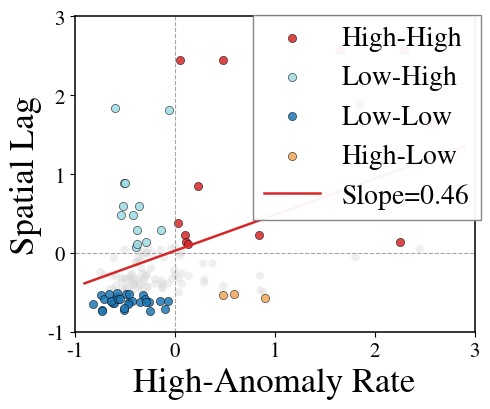

In [45]:
plot_moran_scatter_sig(
    df=geo_data,
    z_col="z_high",
    lag_col="lag_high",
    cluster_col="cluster_high",
    title=None,
    xlabel=r"High-Anomaly Rate",
    ylabel=r"Spatial Lag",
    show_fit=True,
    loc = 'upper right',
    fontsize = 20,
    xlim=(-1,3),
    ylim=(-1,3)
)

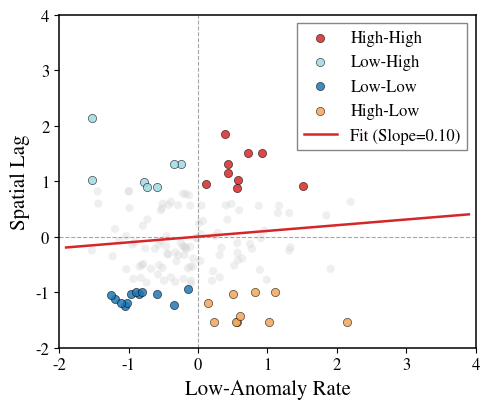

In [160]:
plot_moran_scatter_sig(
    df=geo_data,
    z_col="z_low",
    lag_col="lag_low",
    cluster_col="cluster_low",
    title=None,
    xlabel=r"Low-Anomaly Rate",
    ylabel=r"Spatial Lag",
    show_fit=True,
    loc = 'upper right',
    xlim=(-2,4),
    ylim=(-2,4)
)

In [68]:
boundary_tract = pd.read_csv('../../Data/boundary_data/tal_tract_boundary.csv')
boundary_tract["geometry"] = geopd.GeoSeries.from_wkt(boundary_tract["geometry"])
boundary_tract = geopd.GeoDataFrame(boundary_tract, crs="EPSG:4326")
boundary_tract["centroid"] = geopd.GeoSeries.from_wkt(boundary_tract["centroid"])
boundary_tract.head(2)

,tractID,geoID,geometry,centroid
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473)
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882)


In [69]:
df2 = df2[df2['prop_low'] <= 0.7]
df4 = df2[['badge','tractID','prop_high','prop_low']]
df4 = (
    df4.groupby("tractID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)
df4.head(2)

,tractID,prop_high,prop_low
0,1001,0.088038,0.042146
1,1002,0.082245,0.032264


In [70]:
geo = geopd.GeoDataFrame(boundary_tract).copy()
df4['tractID'] = df4['tractID'].astype(int)
df4['tractID'] = df4['tractID'].astype(str)
geo['tractID'] = geo['tractID'].astype(str)
geo_data = geo.merge(
    df4[["tractID","prop_high","prop_low"]],
    left_on="tractID",
    right_on="tractID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["tractID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(56, 6)


,tractID,geoID,geometry,centroid,prop_high,prop_low
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473),0.105878,0.013713
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882),0.087121,0.013480


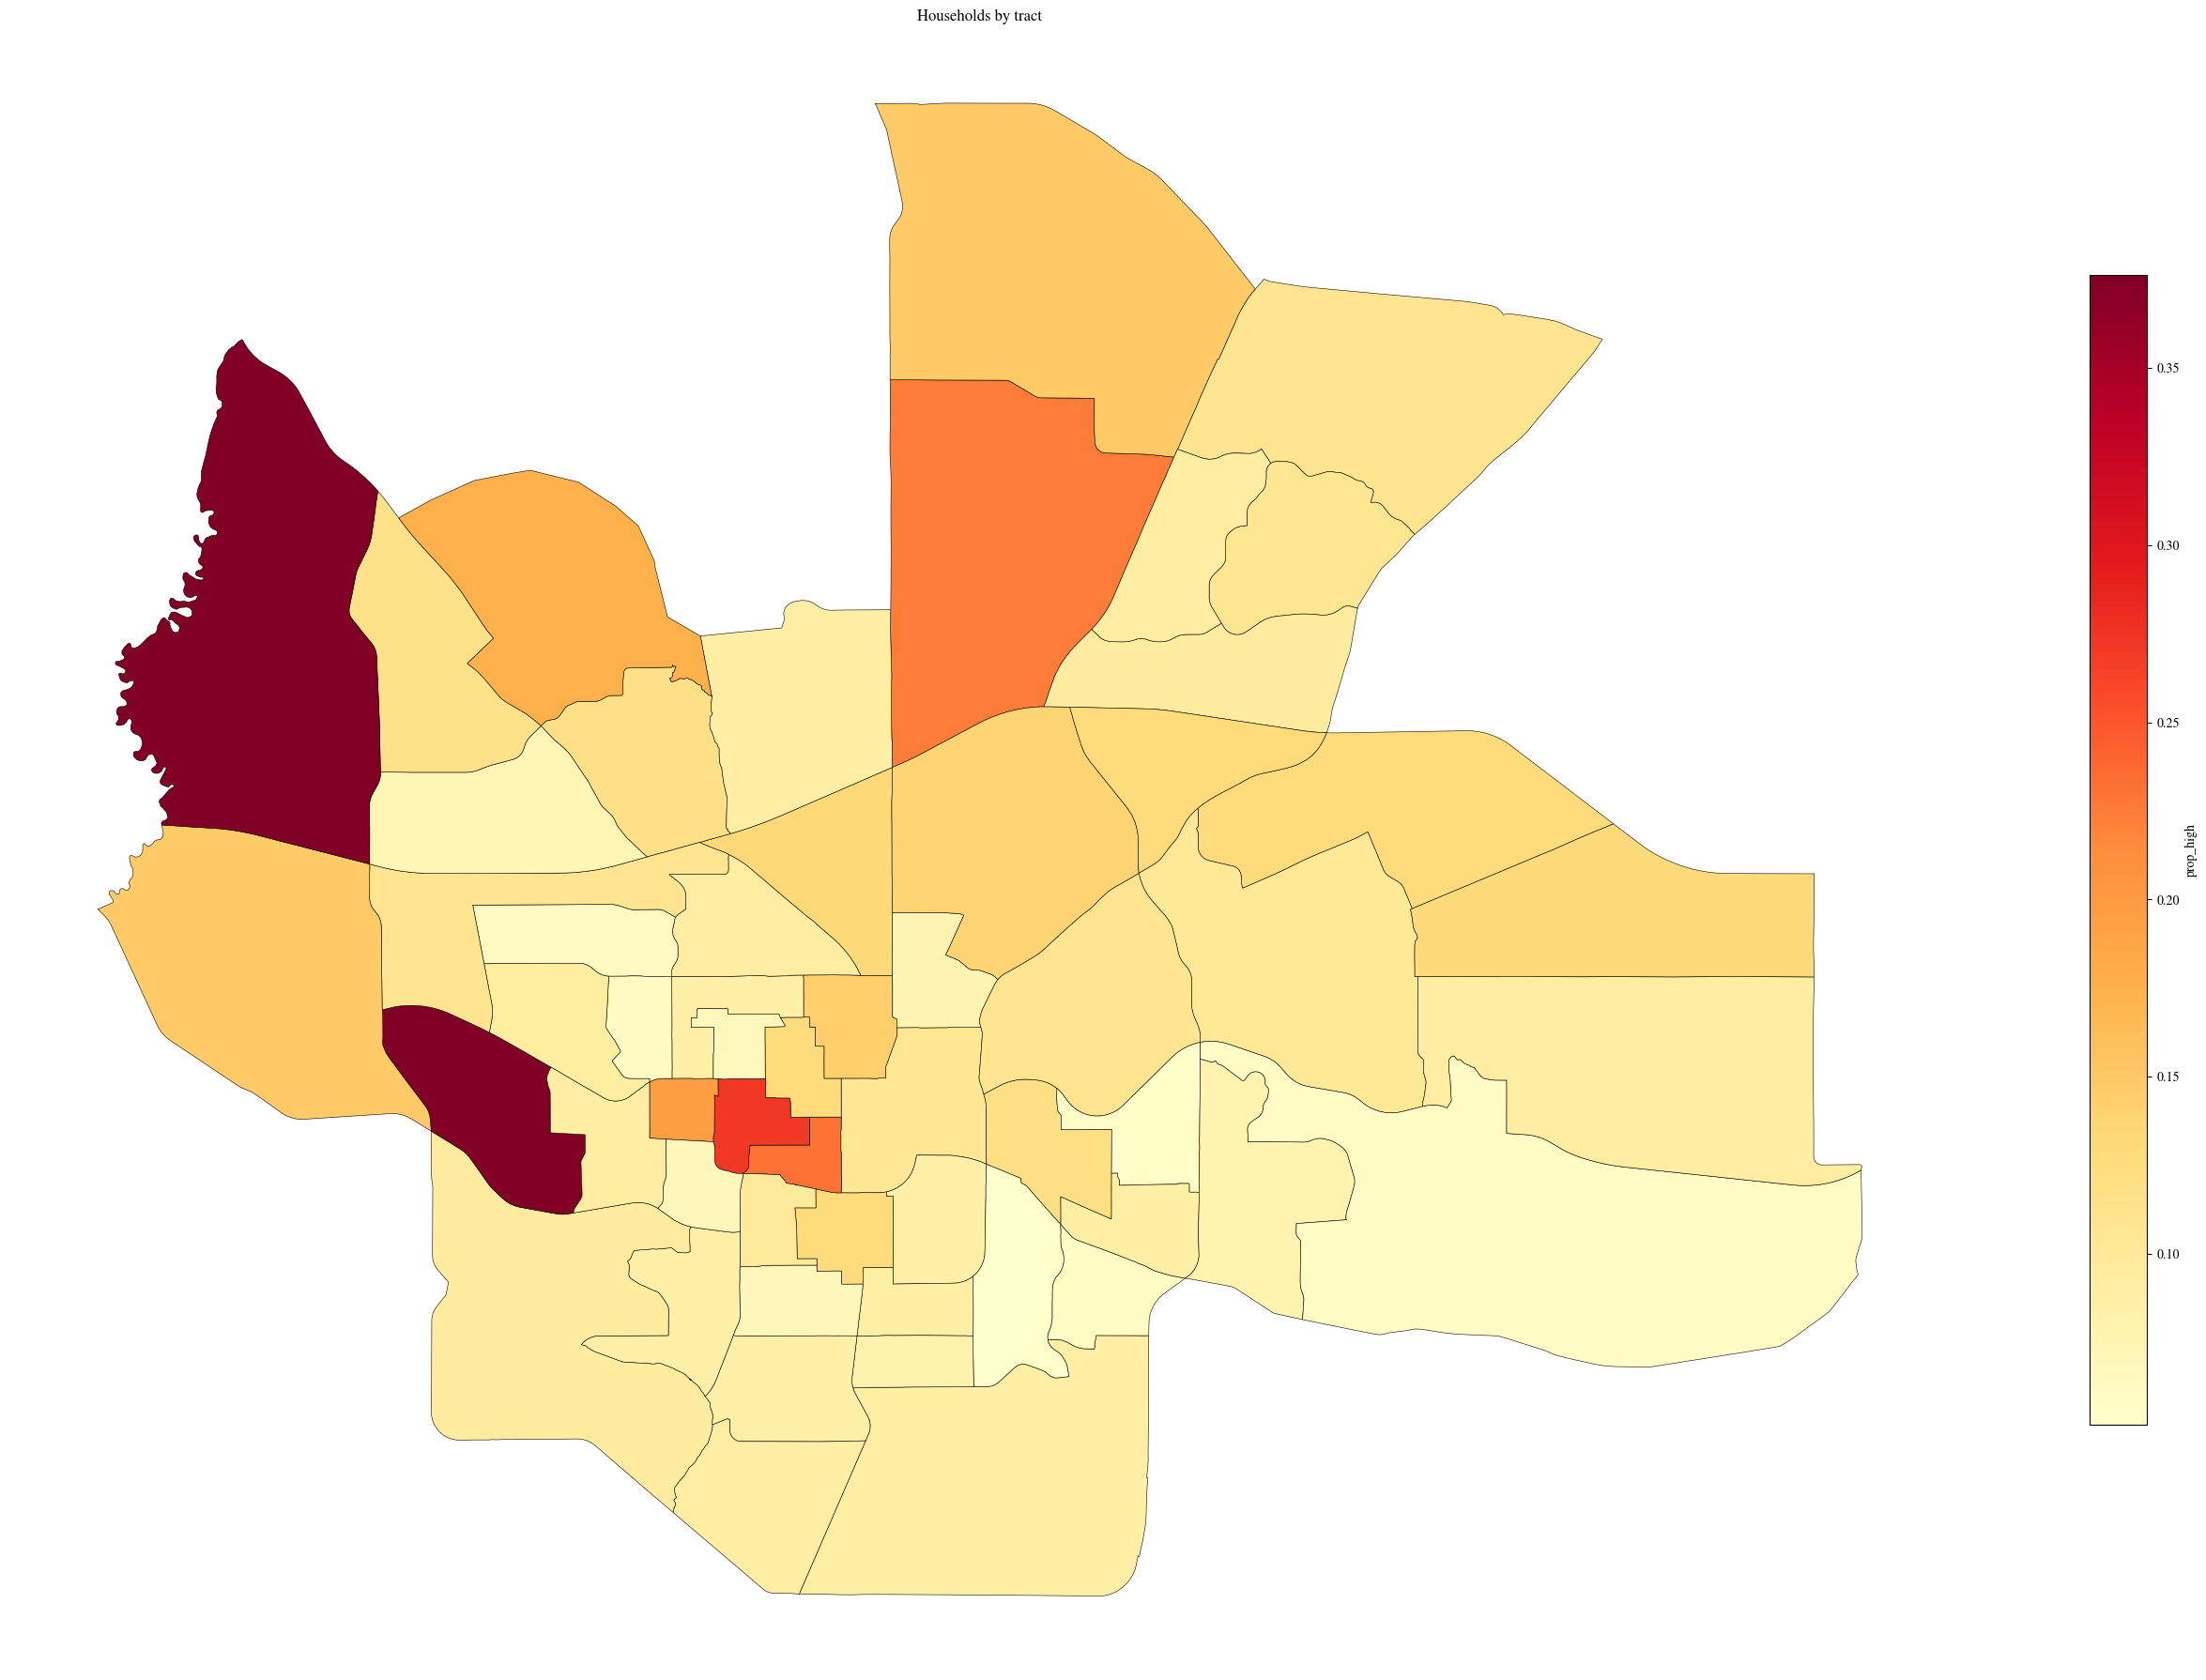

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
# 制图字段（有人口列时可改为 "households"）
color_col = "prop_high"
geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    # vmin=10,
    # vmax=80,
    legend_kwds={
        "label": "prop_high",
        "orientation": "vertical",
        "shrink": 0.7,
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
ax.set_title("Households by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()

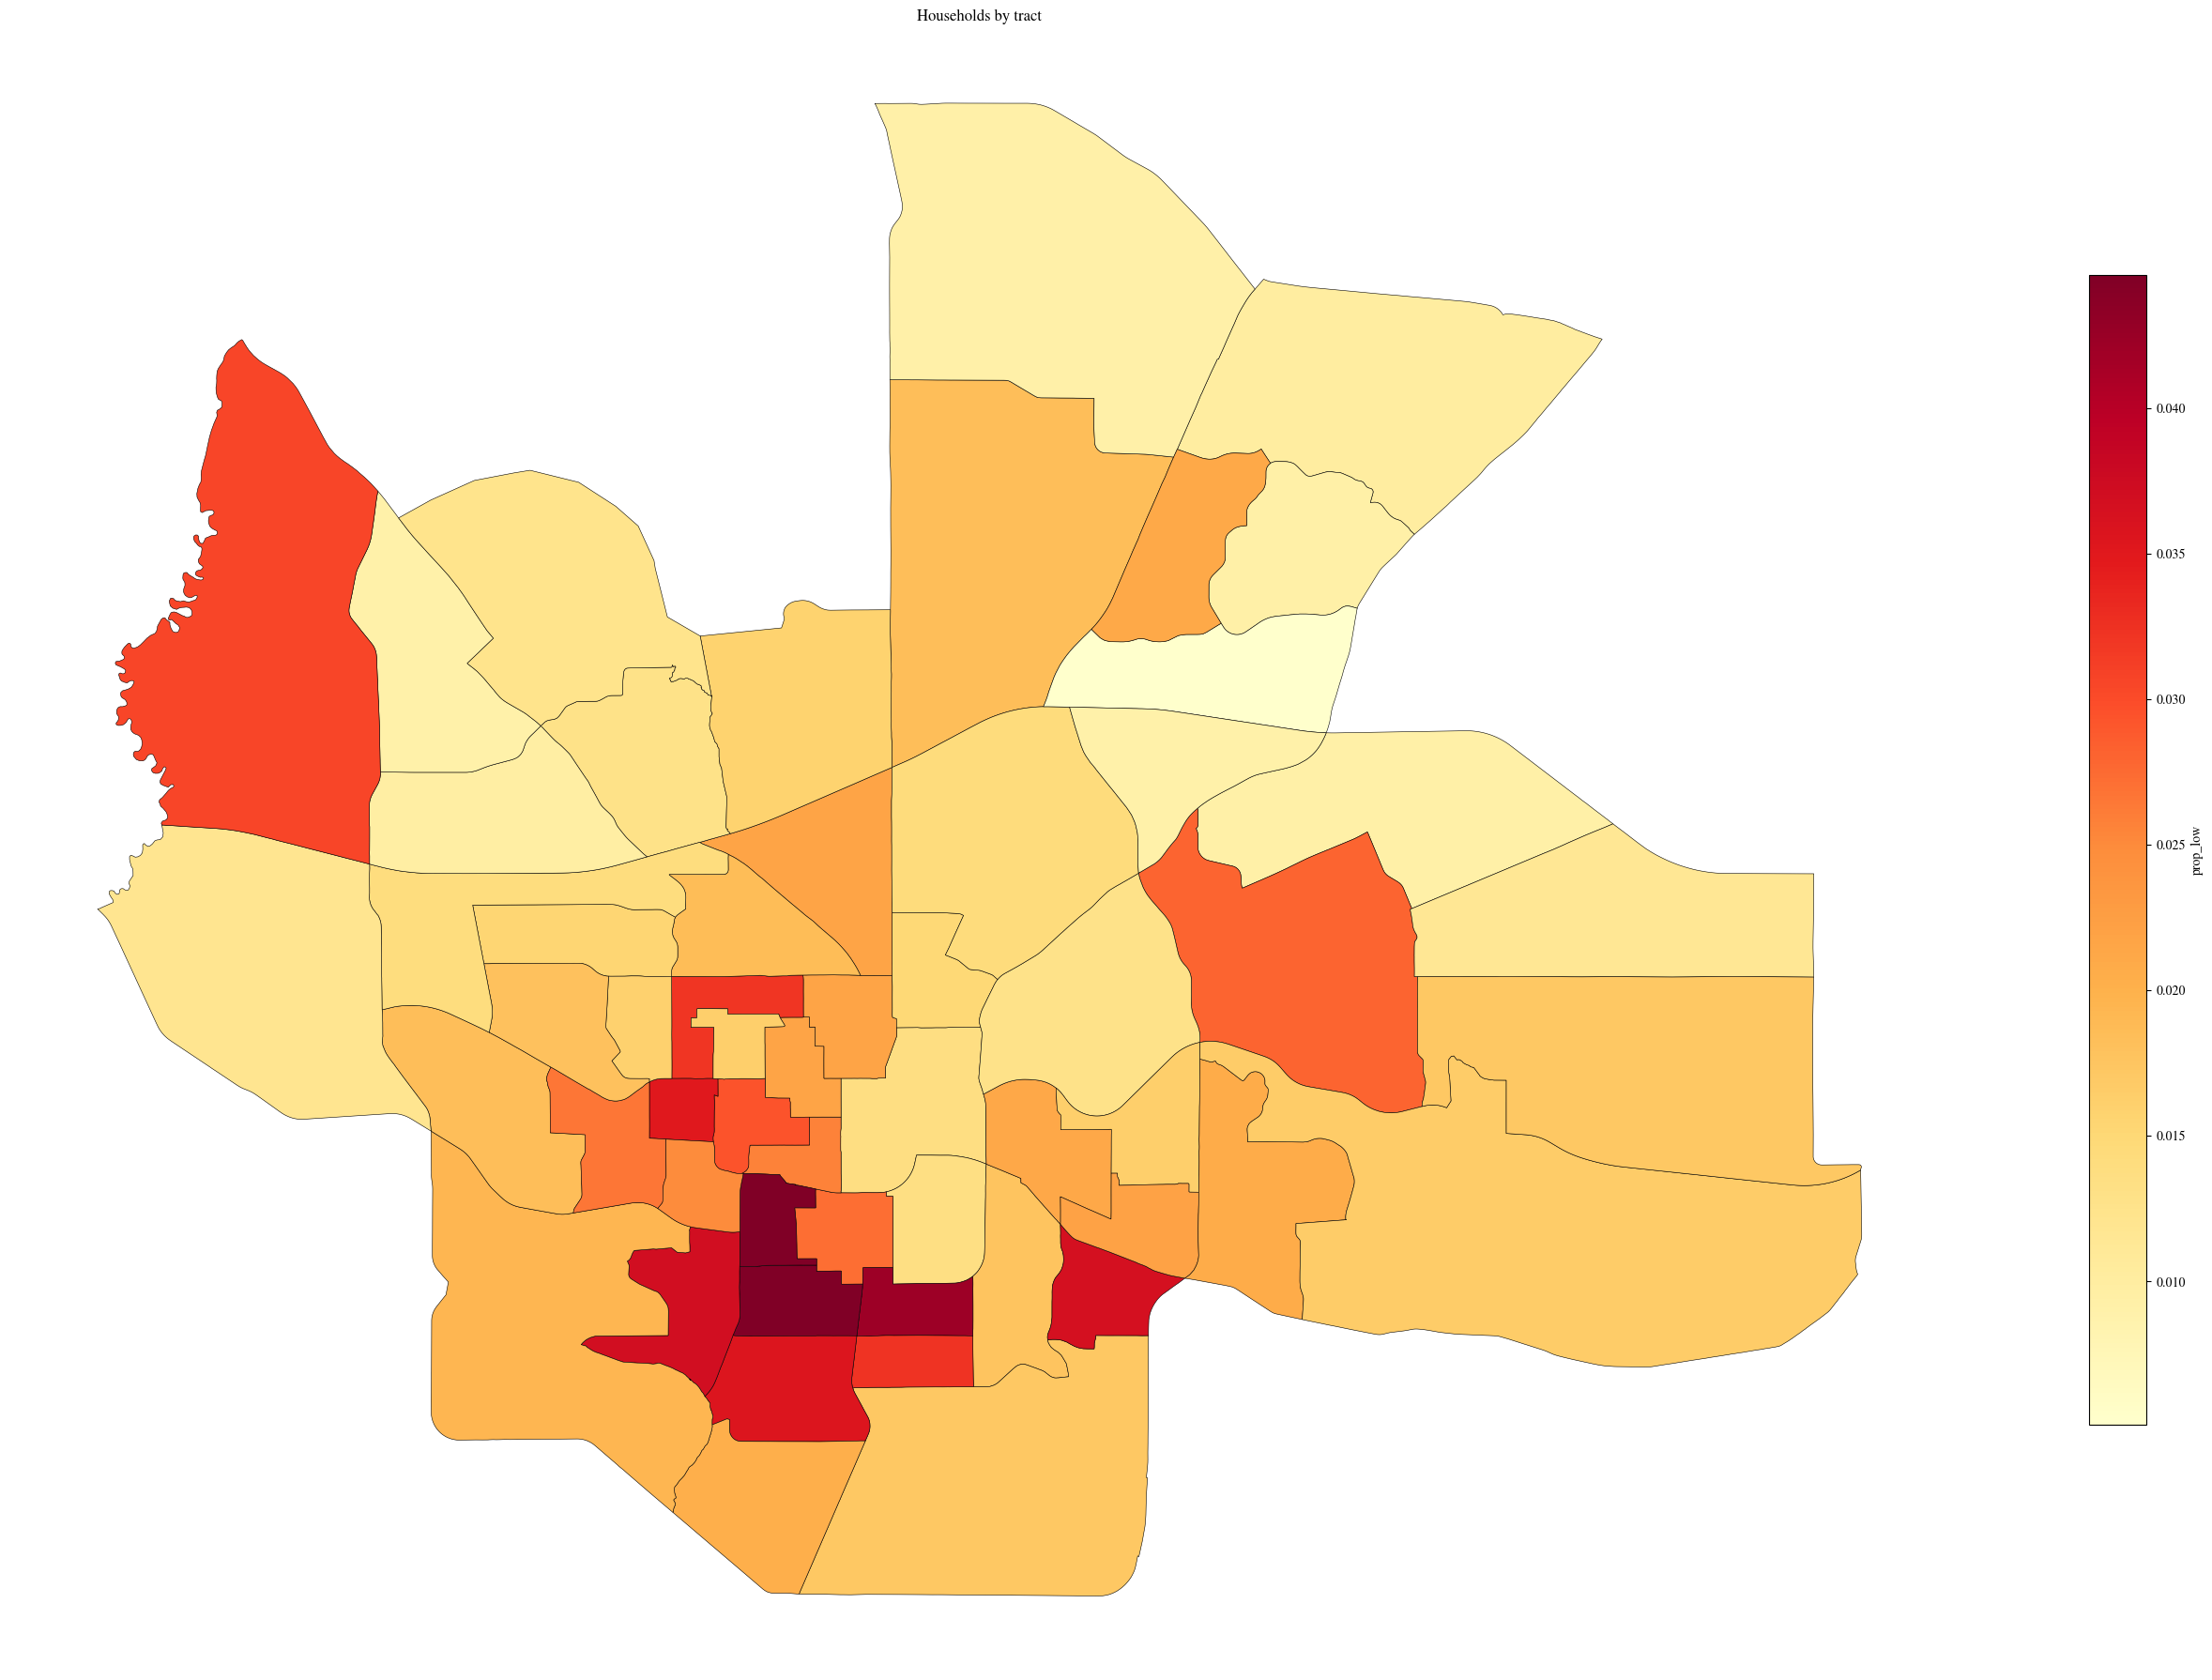

In [72]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
# 制图字段（有人口列时可改为 "households"）
color_col = "prop_low"
geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    # vmin=10,
    # vmax=80,
    legend_kwds={
        "label": "prop_low",
        "orientation": "vertical",
        "shrink": 0.7,
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
ax.set_title("Households by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [90]:
import numpy as np
import geopandas as geopd
from sklearn.neighbors import kneighbors_graph

# 1. 每个 block 只保留一行，保证 W 和 geo_data 一一对应
geo_data = geo_data.drop_duplicates("geoID").copy()
geo_data = geo_data.reset_index(drop=True)

# 2. 确保 centroid 是 GeoSeries
# 如果 centroid 已经是 shapely Point，这一步可以保留，不影响
geo_data["centroid"] = geopd.GeoSeries(geo_data["centroid"], crs="EPSG:4326")

# 3. 用 centroid 构造 GeoDataFrame
centroid_gdf = geopd.GeoDataFrame(
    geo_data[["tractID", "geoID", "prop_high", "prop_low", "centroid"]].copy(),
    geometry="centroid",
    crs="EPSG:4326"
)

# 4. 投影到米制坐标系
centroid_gdf = centroid_gdf.to_crs(epsg=3857)

# 5. 提取 centroid 坐标
coords = np.column_stack([
    centroid_gdf.geometry.x.values,
    centroid_gdf.geometry.y.values
])

# 6. 找最近的 5 个 block，构造 KNN 邻接矩阵
W = kneighbors_graph(
    coords,
    n_neighbors=1,
    mode="connectivity",
    include_self=False
)

# 7. row-normalization
row_sum = np.asarray(W.sum(axis=1)).ravel()
row_sum[row_sum == 0] = 1
W_norm = W.multiply(1 / row_sum[:, None])

In [91]:
from libpysal.weights import WSP
from esda.moran import Moran_Local


def add_local_moran_sig(df, col, W_norm, name, alpha=0.05, permutations=999):
    df = df.copy()

    # convert scipy sparse W to PySAL weights
    w = WSP(W_norm).to_W()
    w.transform = "r"

    # local Moran's I
    lm = Moran_Local(
        df[col].values.astype(float),
        w,
        permutations=permutations
    )

    # save local Moran's I and p-value
    df[f"local_I_{name}"] = lm.Is
    df[f"p_{name}"] = lm.p_sim

    # cluster labels
    z = df[f"z_{name}"].values
    lag = df[f"lag_{name}"].values
    p = df[f"p_{name}"].values

    sig = p < alpha

    df[f"cluster_{name}"] = "Not significant"

    df.loc[(z > 0) & (lag > 0) & sig, f"cluster_{name}"] = "High-High"
    df.loc[(z < 0) & (lag < 0) & sig, f"cluster_{name}"] = "Low-Low"
    df.loc[(z > 0) & (lag < 0) & sig, f"cluster_{name}"] = "High-Low"
    df.loc[(z < 0) & (lag > 0) & sig, f"cluster_{name}"] = "Low-High"

    return df

In [92]:
def add_z_and_lag(df, col, W_norm, name):
    A = df[col].values.astype(float)

    z = (A - A.mean()) / A.std()
    lag = W_norm @ z

    df[f"z_{name}"] = z
    df[f"lag_{name}"] = lag

    return df

geo_data = add_z_and_lag(geo_data, "prop_high", W_norm, "high")
geo_data = add_z_and_lag(geo_data, "prop_low", W_norm, "low")

In [114]:
geo_data = add_local_moran_sig(
    geo_data,
    col="prop_high",
    W_norm=W_norm,
    name="high",
    alpha=0.35,
    permutations=999
)

geo_data = add_local_moran_sig(
    geo_data,
    col="prop_low",
    W_norm=W_norm,
    name="low",
    alpha=0.20,
    permutations=999
)

In [115]:
geo_data.head(2)

,tractID,geoID,geometry,centroid,prop_high,prop_low,z_high,lag_high,z_low,lag_low,local_I_high,p_high,cluster_high,local_I_low,p_low,cluster_low
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473),0.105878,0.013713,-0.182373,0.399690,-0.712106,0.140990,-0.071591,0.160,Low-High,-0.098607,0.312,Not significant
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882),0.087121,0.013480,-0.467185,-0.453252,-0.736722,2.281592,0.207971,0.321,Low-Low,-1.650883,0.035,Low-High


In [141]:
import numpy as np
import matplotlib.pyplot as plt


def plot_moran_scatter_sig(
    df,
    z_col,
    lag_col,
    cluster_col,
    title=None,
    xlabel=r"Standardised Mean Load ($z_i$)",
    ylabel=r"Spatial Lag ($Wz_i$)",
    show_fit=True,
    figsize=(5, 4.2),
    loc = 'upper right',
):
    z = df[z_col].values
    lag_z = df[lag_col].values
    clusters = df[cluster_col].values

    color_map = {
        "High-High": "#d62728",       # red
        "Low-High": "#9edae5",        # light blue
        "Low-Low": "#1f77b4",         # blue
        "High-Low": "#f2a65a",        # orange
        "Not significant": "lightgray"
    }

    plot_order = [
        "Not significant",
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    label_order = [
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    plt.rcParams["font.family"] = "serif"

    fig, ax = plt.subplots(figsize=figsize)

    handles = {}

    # plot points
    for label in plot_order:
        mask = clusters == label
        if mask.sum() == 0:
            continue

        sc = ax.scatter(
            z[mask],
            lag_z[mask],
            s=35,
            c=color_map[label],
            alpha=0.35 if label == "Not significant" else 0.85,
            edgecolor="black" if label != "Not significant" else "none",
            linewidth=0.4,
            label=label
        )

        handles[label] = sc

    # quadrant lines
    ax.axhline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)
    ax.axvline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)

    # fit line
    if show_fit:
        slope, intercept = np.polyfit(z, lag_z, 1)
        x_line = np.linspace(z.min(), z.max(), 100)
        y_line = slope * x_line + intercept

        line, = ax.plot(
            x_line,
            y_line,
            linewidth=1.8,
            color="#d62728",
            label=f"Fit (Slope={slope:.2f})"
        )

        handles["fit"] = line

    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)

    if title is not None:
        ax.set_title(title, fontsize=13)

    ax.tick_params(axis="both", labelsize=12)

    # legend order
    legend_handles = []
    legend_labels = []

    for label in label_order:
        if label in handles:
            legend_handles.append(handles[label])
            legend_labels.append(label)

    if show_fit and "fit" in handles:
        legend_handles.append(handles["fit"])
        legend_labels.append(f"Fit (Slope={slope:.2f})")

    ax.legend(
        legend_handles,
        legend_labels,
        loc=loc,
        frameon=True,
        fancybox=False,
        edgecolor="gray",
        framealpha=0.95,
        fontsize=12
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

    plt.tight_layout()
    plt.show()

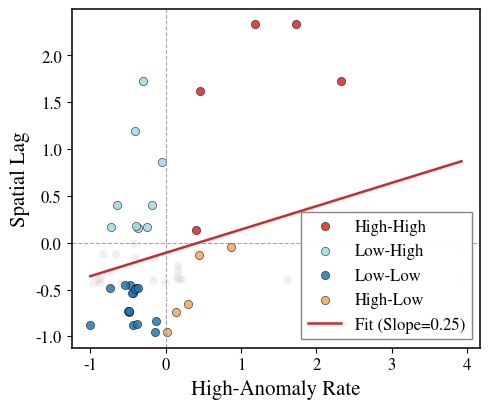

In [142]:
plot_moran_scatter_sig(
    df=geo_data,
    z_col="z_high",
    lag_col="lag_high",
    cluster_col="cluster_high",
    title=None,
    xlabel=r"High-Anomaly Rate",
    ylabel=r"Spatial Lag",
    show_fit=True,
    loc = 'lower right'
)

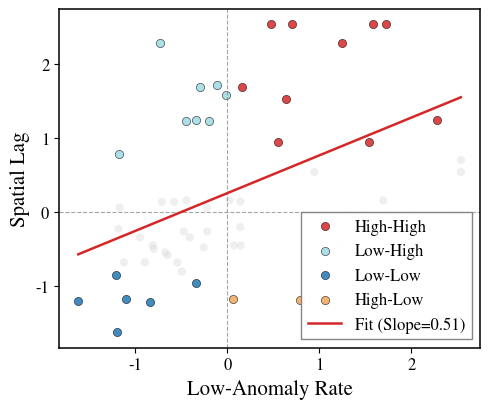

In [143]:
plot_moran_scatter_sig(
    df=geo_data,
    z_col="z_low",
    lag_col="lag_low",
    cluster_col="cluster_low",
    title=None,
    xlabel=r"Low-Anomaly Rate",
    ylabel=r"Spatial Lag",
    show_fit=True,
    loc = 'lower right',
)

## 这两张图表示高异常具有比较明显空间相关性 / 低异常则在随机的同时具有比较明显时间相关性